# 33 · Observability: traces, what to log, and a dashboard
Level L6 · Part 6 · core · ~30 min · builds on 11, 14

## Goal
Record every model call and every tool call in one run as a span, with its start, end, duration, tokens and outcome. Draw the spans as a
flowchart, and print the table a dashboard would plot. Then decide what is safe to log: the decisions and the numbers, not the customer's words.

## Why it matters
When an agent is slow or expensive, the answer is in its steps: which model call took the time, which tool failed, how many tokens each step
used. Without a trace, the team guesses. With a trace, a slow refund run points at the tool that timed out. A trace also holds customer text, so
logging everything is a privacy problem of its own.

| Without a trace | With a trace |
|---|---|
| "The agent was slow" | "The lookup took 4 seconds; the model call took 1" (an example) |
| The bill arrives, with no split | Each span carries its tokens, so the cost has a source |
| Logs hold the customer's words | Logs hold the decision, the step and the numbers |

## The idea
A **trace** is one run. A **span** is one step in it, with a name, a start and end time, and attributes. LangChain calls a callback
for each model call and tool call; the callback writes a span. The span is the unit a dashboard counts: calls per run, tokens per run, latency
per step, errors per tool.

## Picture
`show_mermaid` is a course helper (in `graph_view.py`) that draws a Mermaid flowchart, written as text, inside the notebook.

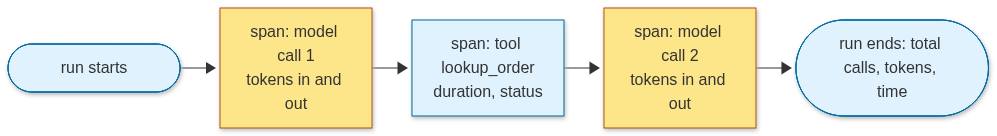

In [1]:
import sys; sys.path.insert(0, "../../..")  # make the topic folder importable

from graph_view import show_mermaid

show_mermaid("""
flowchart LR
  R(["run starts"]) --> M1["span: model call 1<br/>tokens in and out"]
  M1 --> T1["span: tool lookup_order<br/>duration, status"]
  T1 --> M2["span: model call 2<br/>tokens in and out"]
  M2 --> E(["run ends: total calls, tokens, time"])
  classDef model fill:#fde68a,stroke:#b45309
  classDef code fill:#e0f2fe,stroke:#0369a1
  class M1,M2 model
  class R,T1,E code
""")

## Step by step
**Step 1 · the recorder (no call).** `ModelSpans` is a LangChain callback. LangChain calls its methods when a model call starts, ends or
fails, and each call writes one span: name, duration, tokens and outcome. It does not keep the message text.

In [2]:
import time
from langchain_core.callbacks import BaseCallbackHandler


class ModelSpans(BaseCallbackHandler):
    """Writes one span per model call. LangChain calls the on_... methods itself."""

    def __init__(self):
        self.spans: list[dict] = []
        self._open: dict = {}

    def _start(self, run_id, name):
        self._open[run_id] = (name, time.perf_counter())

    def _end(self, run_id, tokens=(0, 0), error=None):
        name, start = self._open.pop(run_id)
        ms = round((time.perf_counter() - start) * 1000)
        self.spans.append({"name": name, "ms": ms, "in": tokens[0], "out": tokens[1],
                           "ok": error is None, "error": error})

    def on_chat_model_start(self, serialized, messages, *, run_id, **kwargs):
        self._start(run_id, "model call")

    def on_llm_start(self, serialized, prompts, *, run_id, **kwargs):
        self._start(run_id, "model call")

    def on_llm_end(self, response, *, run_id, **kwargs):
        usage = response.generations[0][0].message.usage_metadata or {}
        self._end(run_id, tokens=(usage.get("input_tokens", 0), usage.get("output_tokens", 0)))

    def on_llm_error(self, error, *, run_id, **kwargs):
        self._end(run_id, error=type(error).__name__)

**Step 1b · the tool calls (no call).** `TraceRecorder` extends `ModelSpans` with the tool callbacks, so one recorder covers both kinds of call.

In [3]:
class TraceRecorder(ModelSpans):
    """The model spans, plus one span per tool call."""

    def on_tool_start(self, serialized, input_str, *, run_id, **kwargs):
        self._start(run_id, f"tool {serialized.get('name', 'tool')}")

    def on_tool_end(self, output, *, run_id, **kwargs):
        self._end(run_id)

    def on_tool_error(self, error, *, run_id, **kwargs):
        self._end(run_id, error=type(error).__name__)


recorder = TraceRecorder()
print("recorder ready · spans so far:", len(recorder.spans))

recorder ready · spans so far: 0


**Step 2 · one run of the desk, traced (2 model calls).** The desk is the graph from lesson 11: a model step and a lookup step. Three course
helpers come with it, each explained once here. `llm_replay` saves the model's answers the first time and replays them offline, so the lesson
runs with no key. `get_llm` returns the course model (its setup is in `llm_setup.py`). `show_graph` draws a LangGraph graph. The recorder is
passed in the run's config, so every call inside the run is traced without changing the graph.

In [4]:
import json
from pathlib import Path

import llm_replay
llm_replay.start("33_observability")

from langchain_core.messages import HumanMessage
from langchain_core.tools import tool
from pydantic import BaseModel, ConfigDict, Field
from llm_setup import get_llm

llm = get_llm()
ORDERS = json.loads((Path("../../../data") / "support_eval.json").read_text())["world"]["orders"]


class OrderQuery(BaseModel):
    model_config = ConfigDict(extra="forbid")
    order_id: str = Field(description="The order number the customer wrote: four digits, such as 1003.", pattern=r"^\d{4}$")


@tool(args_schema=OrderQuery)
def lookup_order(order_id: str) -> dict:
    """Look up one customer order: its status and days late."""
    return ORDERS.get(order_id, {"error": f"no order {order_id}"})

LLM mode: replay (33_observability.yaml)


Gemini on Vertex AI · API key loaded: True


The graph is a model step, a tool step, and a loop back to the model until it has an answer. Then one traced run.

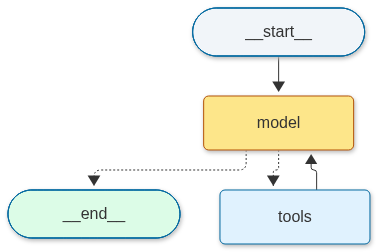

answer length: 275 characters (the text itself is not logged)


In [5]:
from langgraph.graph import END, START, MessagesState, StateGraph
from langgraph.prebuilt import ToolNode, tools_condition
from graph_view import show_graph

model = llm.bind_tools([lookup_order])
g = StateGraph(MessagesState)
g.add_node("model", lambda s: {"messages": [model.invoke(s["messages"])]})
g.add_node("tools", ToolNode([lookup_order]))
g.add_edge(START, "model")
g.add_conditional_edges("model", tools_condition, {"tools": "tools", END: END})
g.add_edge("tools", "model")
desk = g.compile()
show_graph(desk, model_nodes=("model",))

traced = TraceRecorder()
out = desk.invoke({"messages": [HumanMessage(content="Order 1003 never arrived. What is its status?")]},
                  config={"callbacks": [traced]})
print("answer length:", len(out["messages"][-1].text), "characters (the text itself is not logged)")
llm_replay.stop()  # the last model call of this lesson

**Step 3 · the trace as a table (no call).** Each span is one row. The totals at the bottom are what a dashboard would show for the run: calls,
tokens and time. A failed span would show `failed:` and the error name; this run had none. The `ms` column is measured on this machine. In
replay it shows the speed of the replay, not the model's latency: a live run gives real latencies.

In [6]:
print(f"{'span':<22}{'ms':>7}{'in tok':>8}{'out tok':>9}  status")
for s in traced.spans:
    status = "ok" if s["ok"] else f"failed: {s.get('error')}"
    print(f"{s['name']:<22}{s['ms']:>7}{s['in']:>8}{s['out']:>9}  {status}")
print(f"\nrun totals: {len(traced.spans)} spans · {sum(s['in'] + s['out'] for s in traced.spans)} tokens · "
      f"{sum(s['ms'] for s in traced.spans)} ms in spans")

span                       ms  in tok  out tok  status
model call                 78      66       21  ok
tool lookup_order           1       0        0  ok
model call                  6      98       67  ok

run totals: 3 spans · 252 tokens · 85 ms in spans


**Step 4 · the trace as a flowchart (no call).** The same spans drawn in order. The flowchart is built from the trace, so it shows what really ran,
not what the graph was meant to do.

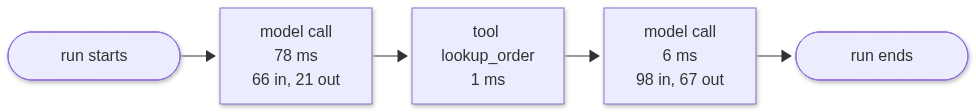

In [7]:
lines = ["flowchart LR", '  S(["run starts"])']
prev = "S"
for i, s in enumerate(traced.spans):
    node = f"n{i}"
    label = f"{s['name']}<br/>{s['ms']} ms" + (f"<br/>{s['in']} in, {s['out']} out" if s["in"] or s["out"] else "")
    lines.append(f'  {node}["{label}"]')
    lines.append(f"  {prev} --> {node}")
    prev = node
lines.append(f'  {prev} --> E(["run ends"])')
show_mermaid("\n".join(lines))

**Step 5 · what is safe to log (no call).** A log record holds the decision and the numbers, not the customer's words, the order's address or
the card. `safe_record` keeps only the allowed fields and drops everything else, so a new field added to a span cannot leak. The demo span
below carries two made-up private fields; the output shows them dropped.

In [8]:
SAFE_FIELDS = {"name", "ms", "in", "out", "ok", "error"}


def safe_record(span: dict) -> dict:
    return {k: v for k, v in span.items() if k in SAFE_FIELDS}


leaky = dict(traced.spans[0], customer_message="Order 1003 never arrived", card="not stored")
print("logged:", safe_record(leaky))

logged: {'name': 'model call', 'ms': 78, 'in': 66, 'out': 21, 'ok': True, 'error': None}


## At real scale
- A dashboard counts spans: calls per run, tokens per run, the slowest tool, the failure rate per tool. Teams set an alert on the failure rate, not on
  one failed run → lesson 32 (evals in CI) and lesson 35 (reliability).
- Traces are the evidence for a cost review. Each span carries its tokens, so the bill can be split by step and by customer type → lesson 36.
- A trace that holds customer text is personal data. Teams log the decision and the numbers only, and keep the text out of every log → lesson 34.

## Decision guide
| Question | Look at |
|---|---|
| Why was this run slow? | The span table (Step 3): the span with the largest `ms` |
| Why did this run cost so much? | Tokens per span: the step with the most input or output tokens |
| Is one tool failing more often this week? | The failure count per tool, counted from the spans |
| What may a log record hold? | The decision, the step and the numbers (Step 5), never the message text |
| Do I need the customer's words to debug? | Usually not. Spans answer the question; text needs its own controls → lesson 34 |

## What just happened
- The run made 2 model calls and 1 tool call: 3 spans, with 252 tokens in total (164 in, 88 out).
- The spans' `ms` column adds up to the total time. The tool span is the shortest. The exact milliseconds change from run to run.
- The answer was 275 characters long. Only that count was printed, not the text.
- `safe_record` kept the 6 allowed fields and dropped the two private ones.

## Common mistakes
1. **Logging the message.** The customer's words end up in every log. Keep the allowed fields only.
2. **A span with no end.** A call that never reports its end looks like it is still running, and any total that needs its duration fails. The
   real error is below. The fix: the error callbacks close the span too (`on_llm_error`, `on_tool_error`), so every span has its `ms`.
3. **Averages only.** One slow tool hides in the average. Look at the slowest span and the failure rate per tool.

In [9]:
open_span = {"name": "tool lookup_order", "in": 0, "out": 0, "ok": True}  # started, never ended: no "ms"
try:
    print(sum(s["ms"] for s in [open_span]))
except KeyError as e:
    print(f"{type(e).__name__}: {e}")

KeyError: 'ms'


## Try it
Write `total_tokens(spans)` that returns the sum of the input and output tokens over the spans. Test it on `traced.spans`. No model call is needed.

In [10]:
# your code here

**Answer** — try it first, then expand the hidden cell below.

In [11]:
def total_tokens(spans: list[dict]) -> int:
    return sum(s["in"] + s["out"] for s in spans)


print(total_tokens(traced.spans))

252


## Key terms
- **Trace** — the record of one whole run, made of its spans.
- **Span** — one step inside a trace (one model call or one tool call), with its name, duration, tokens and outcome.
- **Callback** — a method LangChain calls at a set point (a call starts, ends or fails); the recorder writes spans from these.

## Recap
- A trace is one run; a span is one call inside it, with time, tokens and outcome.
- A callback writes the spans, so the graph does not change.
- Log the decision and the numbers. Never the customer's words.

**Interview:** "A refund run took 40 seconds yesterday. How do you find out why?" Strong answer: "Each model and tool call is a span with its duration. I look at
the trace for that run, find the slowest span, and check the failure rate of that tool over the week. I don't need the customer's text to find the slow step."